In [2]:
# %% Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV,
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score, recall_score,
    precision_score, f1_score, confusion_matrix, classification_report, RocCurveDisplay,
)

RANDOM_STATE = 42
DATA_PATH = "/content/data/drinking_water_potability.csv"
os.makedirs("images", exist_ok=True)

In [3]:

# %% Load data
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("\nClass balance:")
print(df["Potability"].value_counts())
print(df["Potability"].value_counts(normalize=True).round(3))
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Shape: (3276, 10)

Class balance:
Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64

Missing values per column:
ph                 491
Sulfate            781
Trihalomethanes    162
dtype: int64


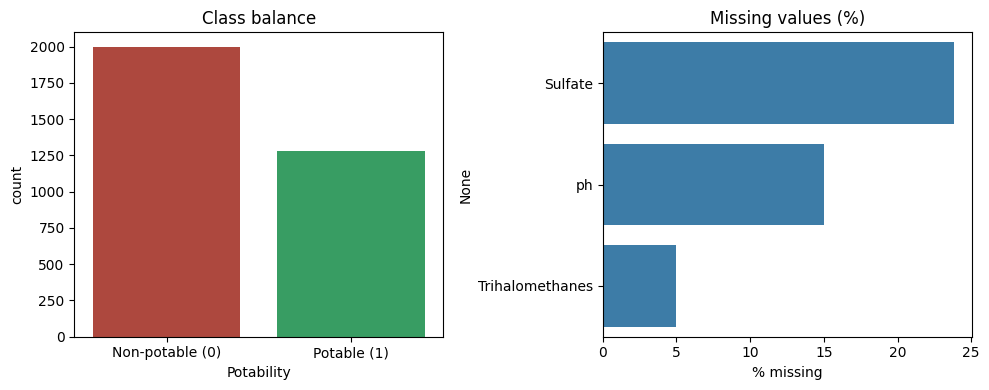

In [4]:

# %% Class balance and missing values plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Potability", data=df, hue="Potability", palette=["#c0392b", "#27ae60"],
              legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Non-potable (0)", "Potable (1)"])
axes[0].set_title("Class balance")
missing = df.isnull().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
sns.barplot(x=missing.values, y=missing.index, color="#2c7fb8", ax=axes[1])
axes[1].set_title("Missing values (%)")
axes[1].set_xlabel("% missing")
plt.tight_layout()
plt.savefig("images/class_balance_missing.png", dpi=150)
plt.show()

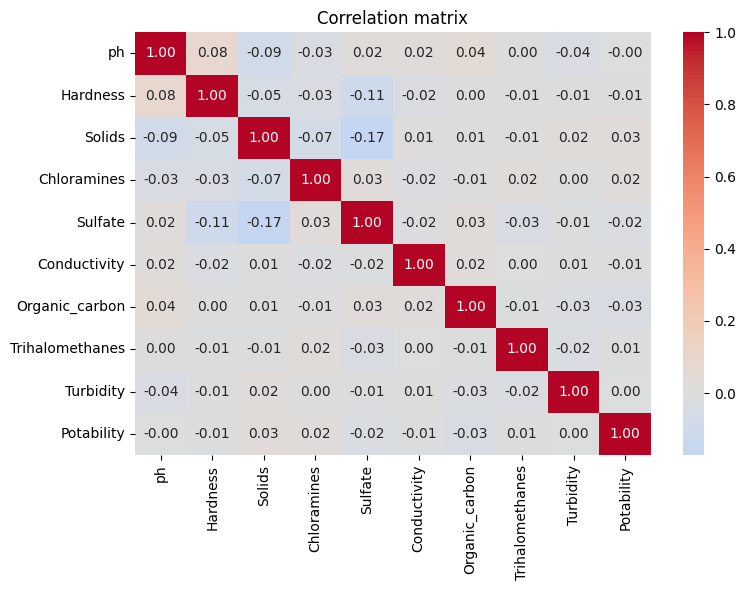

Correlation of each feature with Potability:
Organic_carbon    -0.030
Sulfate           -0.024
Hardness          -0.014
Conductivity      -0.008
ph                -0.004
Turbidity          0.002
Trihalomethanes    0.007
Chloramines        0.024
Solids             0.034
Name: Potability, dtype: float64


In [5]:

# %% Correlation heatmap (are any single features predictive?)
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150)
plt.show()
print("Correlation of each feature with Potability:")
print(df.corr()["Potability"].drop("Potability").round(3).sort_values())

In [6]:
# %% Stratified train / test split (raw data, no imputation or scaling yet)
X = df.drop(columns="Potability")
y = df["Potability"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share potable - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (2620, 9) | Test: (656, 9)
Share potable - train: 0.390, test: 0.390


In [7]:

# %% Candidate models (every preprocessing step is inside the pipeline)
impute = lambda: SimpleImputer(strategy="median")

models = {
    "Baseline (always non-potable)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        impute(), StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision tree (depth 5)": make_pipeline(
        impute(), DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
    "Random forest (default)": make_pipeline(
        impute(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),  # handles NaN natively
}

# %% 5-fold stratified cross-validation on the TRAINING set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC": f"{scores['test_roc_auc'].mean():.3f} +/- {scores['test_roc_auc'].std():.3f}",
        "CV accuracy": f"{scores['test_accuracy'].mean():.3f} +/- {scores['test_accuracy'].std():.3f}",
        "CV balanced acc.": f"{scores['test_balanced_accuracy'].mean():.3f}",
        "_auc_mean": scores["test_roc_auc"].mean(),
    })
cv_table = pd.DataFrame(cv_rows)
print(cv_table.drop(columns="_auc_mean").to_string(index=False))

                        Model      CV ROC-AUC     CV accuracy CV balanced acc.
Baseline (always non-potable) 0.500 +/- 0.000 0.610 +/- 0.001            0.500
          Logistic regression 0.477 +/- 0.018 0.495 +/- 0.016            0.489
      Decision tree (depth 5) 0.578 +/- 0.035 0.637 +/- 0.010            0.558
      Random forest (default) 0.686 +/- 0.015 0.676 +/- 0.006            0.617
            Gradient boosting 0.667 +/- 0.015 0.653 +/- 0.013            0.610


In [9]:
# %% Tune the random forest on the TRAINING set only (cross-validated, scored by ROC-AUC)
rf_pipe = make_pipeline(impute(), RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
param_grid = {
    "randomforestclassifier__n_estimators": [200],
    "randomforestclassifier__max_depth": [5, 10, None],
    "randomforestclassifier__min_samples_leaf": [1, 3],
    "randomforestclassifier__max_features": ["sqrt"],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC: %.3f" % grid.best_score_)
best_rf = grid.best_estimator_

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 200}
Best CV ROC-AUC: 0.682


In [10]:

# %% Choose the decision threshold from out-of-fold predictions on the TRAINING set
# (the default 0.5 gives poor recall for the minority "potable" class)
oof_proba = cross_val_predict(best_rf, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.arange(0.20, 0.71, 0.01)
bal_acc = [balanced_accuracy_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(bal_acc))])
print("Threshold chosen on training data (max balanced accuracy): %.2f" % best_threshold)

Threshold chosen on training data (max balanced accuracy): 0.45


In [11]:

# %% FINAL evaluation on the held-out test set (used once)
def bootstrap_ci(y_true, values, metric, n=1000, seed=RANDOM_STATE):
    """95% bootstrap confidence interval of a metric on the test set."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    values = np.asarray(values)
    stats = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric(y_true[idx], values[idx]))
    return np.percentile(stats, [2.5, 97.5])


test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_rows.append({
        "Model": name, "Threshold": 0.5,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced acc.": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Potable recall": recall_score(y_test, pred, zero_division=0),
        "Potable precision": precision_score(y_test, pred, zero_division=0),
    })

In [12]:

# Tuned random forest (final model), at the default and at the CV-chosen threshold
proba_test = best_rf.predict_proba(X_test)[:, 1]
for label, thr in [("Random forest (tuned)", 0.5),
                   (f"Random forest (tuned, threshold {best_threshold:.2f})", best_threshold)]:
    pred = (proba_test >= thr).astype(int)
    test_rows.append({
        "Model": label, "Threshold": thr,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced acc.": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba_test),
        "Potable recall": recall_score(y_test, pred),
        "Potable precision": precision_score(y_test, pred),
    })

results = pd.DataFrame(test_rows).round(3)
print(f"Held-out test set: {len(y_test)} samples, {y_test.mean():.1%} potable")
print(results.to_string(index=False))
results.to_csv("results.csv", index=False)

# 95% confidence intervals for the tuned random forest
pred_final = (proba_test >= 0.5).astype(int)
acc_ci = bootstrap_ci(y_test, pred_final == y_test.values, lambda t, v: v.mean())
auc_ci = bootstrap_ci(y_test, proba_test, roc_auc_score)
print("\nTuned RF test accuracy 95%% CI: %.3f - %.3f" % tuple(acc_ci))
print("Tuned RF test ROC-AUC  95%% CI: %.3f - %.3f" % tuple(auc_ci))

print("\nClassification report, tuned RF at threshold %.2f:" % best_threshold)
pred_thr = (proba_test >= best_threshold).astype(int)
print(classification_report(y_test, pred_thr, target_names=["Non-potable", "Potable"], digits=3))

Held-out test set: 656 samples, 39.0% potable
                                Model  Threshold  Accuracy  Balanced acc.  ROC-AUC  Potable recall  Potable precision
        Baseline (always non-potable)       0.50     0.610          0.500    0.500           0.000              0.000
                  Logistic regression       0.50     0.524          0.526    0.547           0.531              0.415
              Decision tree (depth 5)       0.50     0.649          0.572    0.604           0.219              0.651
              Random forest (default)       0.50     0.666          0.605    0.657           0.324              0.643
                    Gradient boosting       0.50     0.655          0.606    0.662           0.383              0.590
                Random forest (tuned)       0.50     0.663          0.604    0.653           0.336              0.628
Random forest (tuned, threshold 0.45)       0.45     0.659          0.612    0.653           0.402              0.592

Tuned RF 

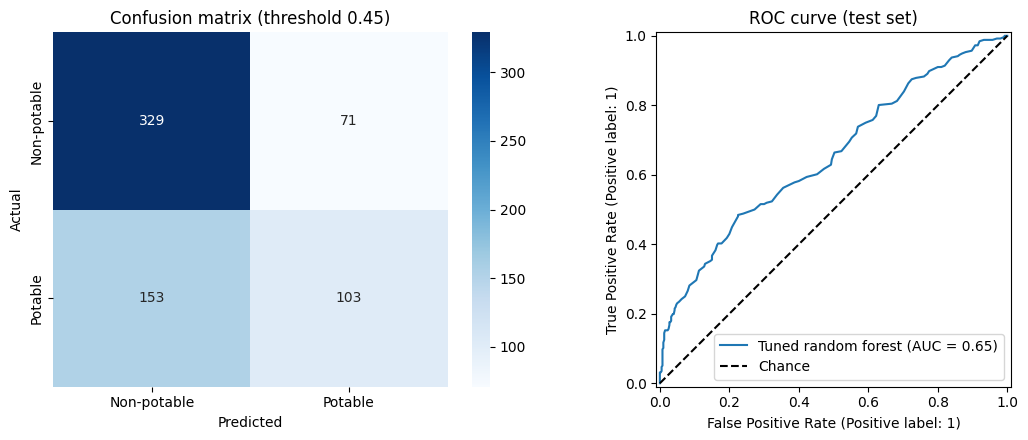

In [13]:

# %% Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm = confusion_matrix(y_test, pred_thr)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Non-potable", "Potable"], yticklabels=["Non-potable", "Potable"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title(f"Confusion matrix (threshold {best_threshold:.2f})")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name="Tuned random forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.savefig("images/confusion_matrix_roc.png", dpi=150)
plt.show()

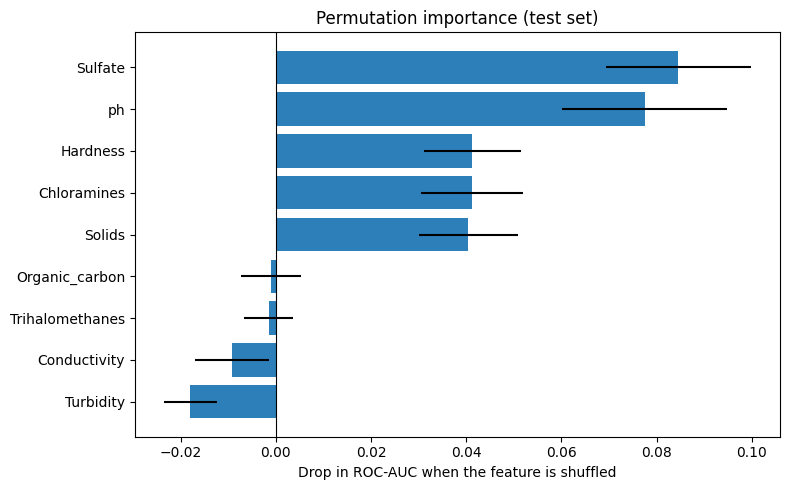

        feature  importance    std
        Sulfate      0.0845 0.0152
             ph      0.0775 0.0173
       Hardness      0.0412 0.0102
    Chloramines      0.0412 0.0107
         Solids      0.0405 0.0105
 Organic_carbon     -0.0010 0.0063
Trihalomethanes     -0.0015 0.0051
   Conductivity     -0.0092 0.0077
      Turbidity     -0.0180 0.0055


In [14]:

# %% Which features matter? Permutation importance on the test set
imp = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc",
                             n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({"feature": X.columns, "importance": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("importance")
plt.figure(figsize=(8, 5))
plt.barh(imp_df["feature"], imp_df["importance"], xerr=imp_df["std"], color="#2c7fb8")
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.savefig("images/permutation_importance.png", dpi=150)
plt.show()
print(imp_df.sort_values("importance", ascending=False).round(4).to_string(index=False))

In [15]:


example = pd.DataFrame([{
    "ph": 7.0, "Hardness": 190.0, "Solids": 20000.0, "Chloramines": 7.0, "Sulfate": 333.0,
    "Conductivity": 420.0, "Organic_carbon": 14.0, "Trihalomethanes": 66.0, "Turbidity": 4.0,
}])
p = best_rf.predict_proba(example)[0, 1]
print(f"Probability potable: {p:.2f} -> {'Potable' if p >= best_threshold else 'Non-potable'}")

Probability potable: 0.17 -> Non-potable
